# White House Visitor Operations and Demand Planning

**Author:** Violetta Kalinicheva  
**Updated:** October 28, 2026  
**Modified by:** Violetta Kalinicheva

### Decision and audience

What can published appointment records tell operations analysts about historical workload concentration, without overstating attendance or exposing visitors? This descriptive study harmonizes 25 public releases and summarizes scheduled dates at monthly and broad location levels. A row is a disclosed appointment-access record: **not a unique person, realized visit, meeting, or unit of staff work**.

The disclosure policy has explicit privacy, staff, sensitive-meeting, and national-security exclusions. Therefore these releases are not a census of all White House activity. The outputs are a historical planning input, not a staffing forecast or an operational security recommendation.

## 1. Preserve, audit, and reconcile

The executable workflow reads every frozen raw source, verifies SHA-256 hashes, and fails on an unexpected snapshot. Only aggregate summaries are printed. Set `PROJECT_DATA_DIR` to the external data folder before execution; see the README for acquisition and ethical boundaries.

In [1]:
# I am starting from the raw snapshot so saved outputs cannot conceal missing steps.
import json
from pathlib import Path
from IPython.display import display
import analysis
analysis.setup()
data, facts = analysis.load_and_audit()
display(__import__('pandas').DataFrame(facts['inventory']).drop(columns='sha256'))
print(json.dumps({k:v for k,v in facts.items() if k != 'inventory'}, indent=2))

Matplotlib is building the font cache; this may take a moment.


,file,rows,columns,exact_duplicates_removed_within_file,invalid_start_dates
0,2021_WAVES-ACCESS-RECORDS White House.csv,41412,27,7,0
1,2022.01_WAVES-ACCESS-RECORDS.csv,1185,27,1,0
2,2022.02_WAVES-ACCESS-RECORDS.csv,2155,27,0,0
3,2022.03_WAVES-ACCESS-RECORDS-.csv,6065,29,2,0
4,2022.04_WAVES-ACCESS-RECORDS.csv,13524,27,5,0
5,2022.05-WAVES-ACCESS-RECORDS.csv,20105,27,6,0
6,2022.06_WAVES-ACCESS-RECORDS.csv,17400,27,4,0
7,2022.07_WAVES-ACCESS-RECORDS.csv,39780,27,20,0
8,2022.08_WAVES-ACCESS-RECORDS.csv,31055,27,20,0
9,2022.09_WAVES-ACCESS-RECORDS.csv,37269,27,15,0


{
  "raw_rows": 1207458,
  "source_files": 25,
  "exact_duplicates_removed_within_file": 1202,
  "rows_after_within_file_deduplication": 1206256,
  "cross_release_repeated_row_hashes": 0,
  "invalid_start_dates": 0,
  "valid_dates_outside_scope": 0,
  "analysis_records": 1206256,
  "first_date": "2021-01-20",
  "last_date": "2023-12-31",
  "months_present": 36,
  "missing_by_selected_field": {
    "Appointment Start Date": 0,
    "Meeting Location": 0,
    "Appointment Cancel Date": 1205441
  },
  "cancel_field_nonmissing": 815,
  "cancel_field_parsed": 812
}


## 2. Establish published activity

How did disclosed scheduled-record counts change across the historical window?

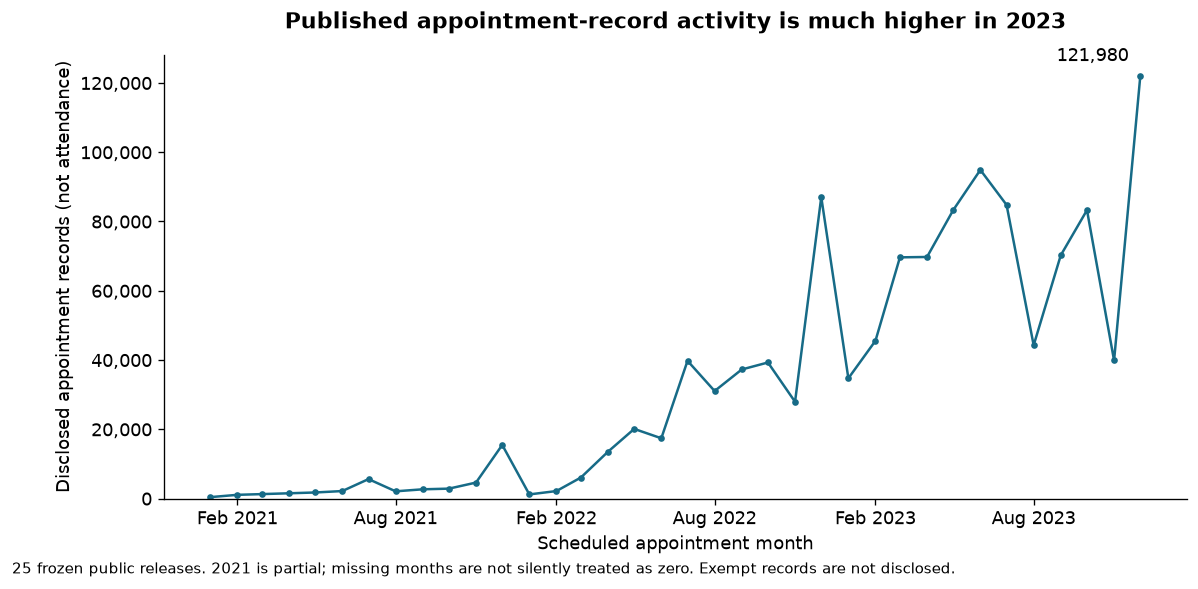

,year,appointment_records
0,2021,41405
1,2022,322689
2,2023,842162


In [2]:
# I am checking this comparison before interpreting the visual.
result = analysis.monthly_story(data, facts)
display(result)

### Interpretation

After within-file exact-row deduplication, annual disclosed-record totals are 41,405 (2021), 322,689 (2022), and 842,162 (2023). The highest month is December 2023 with 121,980 records. Calendar 2021 has different policy and activity coverage from 2022–2023. Higher 2023 counts do not establish higher unique attendance or a stable long-run growth rate.

## 3. Retain the dominant location

Where is the recorded activity concentrated when the largest code is not excluded?

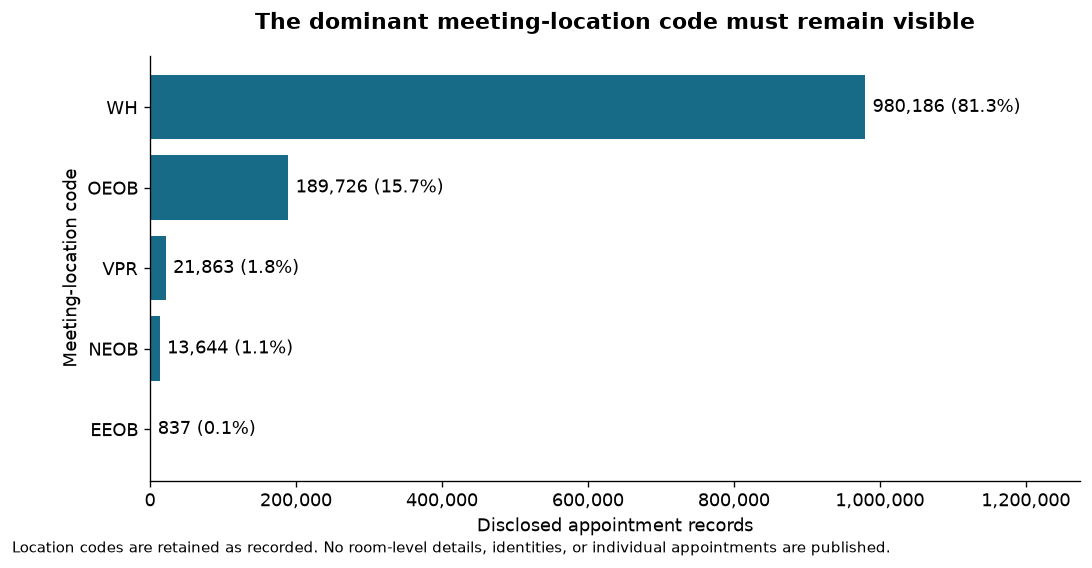

,records
EEOB,837
NEOB,13644
VPR,21863
OEOB,189726
WH,980186


In [3]:
# I am checking this comparison before interpreting the visual.
result = analysis.location_story(data, facts)
display(result)

### Interpretation

WH represents 980,186 records, or 81.3% of the retained snapshot. The original analysis removed this dominant location when ranking other codes. This version keeps it in context rather than implying the non-WH ranking represents all activity. Codes are preserved without inventing definitions; no room-level or named-person analysis is published.

## 4. Stress-test a typical-day plan

How much does an average or median observed day hide the upper tail?

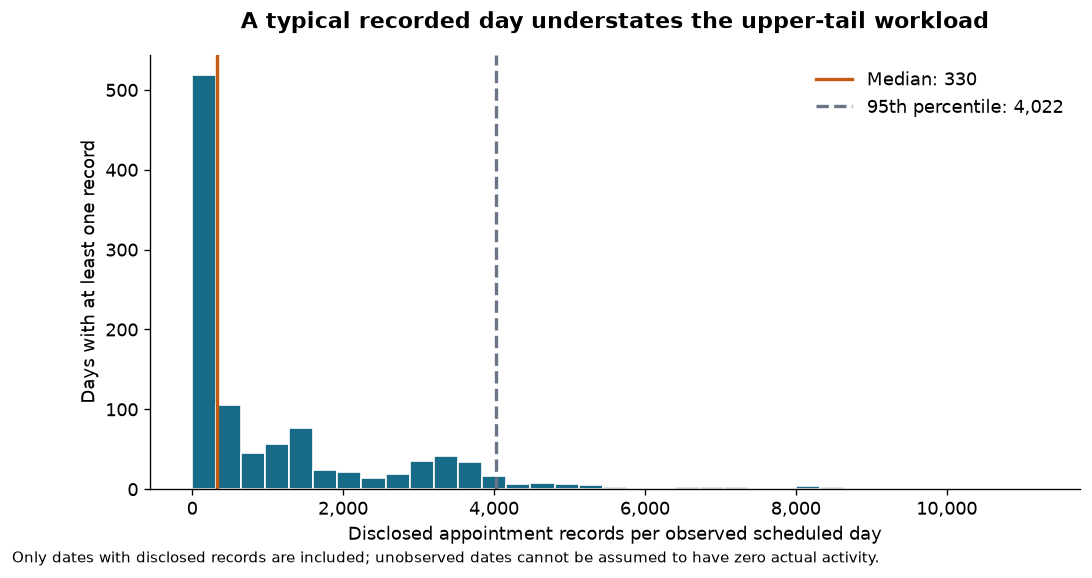

,records_per_observed_day
count,1053.000000
mean,1145.542260
std,1616.513145
min,1.000000
50%,330.000000
90%,3412.800000
95%,4021.600000
99%,7833.840000
max,11205.000000


In [4]:
# I am checking this comparison before interpreting the visual.
result = analysis.workload_story(data, facts)
display(result)

### Interpretation

Among 1,053 days with at least one disclosed record, the median is 330 records, the 95th percentile approximately 4,022, and the largest count is 11,205. High-volume dates can make a single typical-day estimate inadequate, but this is not a staffing requirement: scheduled records can be canceled, repeated, or associated with large events. Unobserved dates are not assumed to have zero actual activity.

## 5. Separate coverage from seasonality

Do three uneven historical years justify a seasonal forecast?

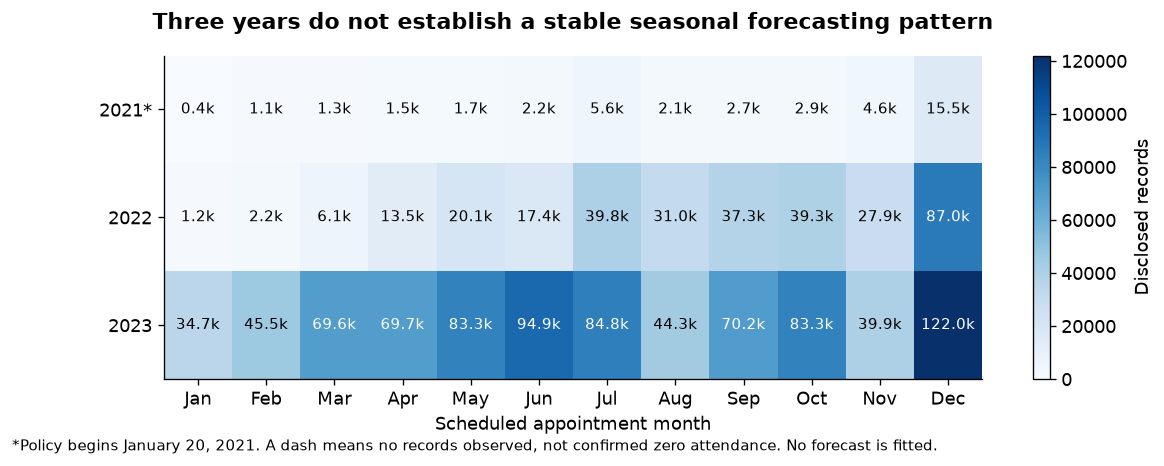

date,1,2,3,4,5,6,7,8,9,10,11,12
date,,,,,,,,,,,,
2021,400,1064,1274,1509,1742,2154,5605,2078,2658,2852,4603,15466
2022,1184,2155,6063,13519,20099,17396,39760,31035,37254,39277,27929,87018
2023,34709,45543,69634,69741,83290,94884,84774,44259,70225,83267,39856,121980


In [5]:
# I am checking this comparison before interpreting the visual.
result = analysis.calendar_story(data, facts)
display(result)

### Interpretation

The calendar reveals uneven observed activity and partial 2021 coverage, not a validated recurring seasonal law. A forecast is deliberately not fitted to only three heterogeneous years. A defensible next step would reconcile disclosed records with aggregate realized arrivals, cancellations, event calendars, and actual staffing before testing a time-based forecast.

## Conclusion and call to action

Use broad disclosed-record aggregates to flag workload concentration and request better operational measures, not to identify visitors or infer political influence. Keep the dominant location in view; distinguish missing coverage from zero; distinguish an appointment row from actual attendance. Plan flexible capacity only after validating aggregate arrivals and service-time measures.

### Cleaning, design, and ethical considerations

Original raw files are unchanged and live outside this repository. Each file is read separately as strings, legacy headers are harmonized, exact duplicate rows are removed **within a release**, dates are parsed with invalid values counted, and valid scheduled dates outside January 20, 2021–December 31, 2023 are excluded from the story and disclosed in metrics. Cross-release repeated row hashes are only a sensitivity audit, not a claim of repeated people. Missing cancellation fields mean no recorded cancellation, not confirmed attendance. `Total People` is never summed because the same appointment group may occur on multiple person records. No identities, row samples, rooms, names, access identifiers, or daily schedules are exported. Figures use monthly aggregates or a histogram over dates.

### References

[Archived official visitor-log releases](https://bidenwhitehouse.archives.gov/disclosures/visitor-logs/), [voluntary disclosure policy](https://bidenwhitehouse.archives.gov/voluntary-disclosure/), and [copyright policy](https://bidenwhitehouse.archives.gov/copyright/) checked October 28, 2026. Government-produced material is not copyright protected according to that policy; this package nevertheless does not redistribute person-level logs. Original code and writing: MIT. `sources.json` lists release URLs and frozen hashes.

In [6]:
# I am recording actual rerun findings and confirming source preservation.
manifest = json.loads(Path('sources.json').read_text())
import os
source_folder = Path(os.environ['PROJECT_DATA_DIR'])
assert all(analysis.source_hash(source_folder / x['file']) == x['sha256'] for x in manifest['files'])
facts['raw_sources_unchanged'] = True
Path('outputs/metrics.json').write_text(json.dumps(facts, indent=2) + '\n')
print('All assertions passed; raw source hashes unchanged. Aggregate outputs only.')

All assertions passed; raw source hashes unchanged. Aggregate outputs only.
